In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MultipleLocator
import numpy as np
from tqdm import tqdm

from pathlib import Path
sys.path.append(str(Path.cwd().parents[0] / "src"))
from Moire_v2 import Moire
import utils

In [35]:
sys = Moire(theta_deg=3.0, psi_deg=0.0, V=8.0, n_shells=8)

In [103]:
Vs = np.linspace(4.0, 14.0, 20)
thetas = np.linspace(1.5, 4.0, 20)

bw = np.empty((len(Vs), len(thetas)))

for i, V in enumerate(tqdm(Vs)):
    sys.V = V                       # <-- set the parameter
    for j, theta in enumerate(thetas):
        sys.theta_deg = theta       # <-- set the parameter
        bw[i, j] = sys.calculate_bandwidth()

100%|██████████| 20/20 [00:02<00:00,  6.84it/s]


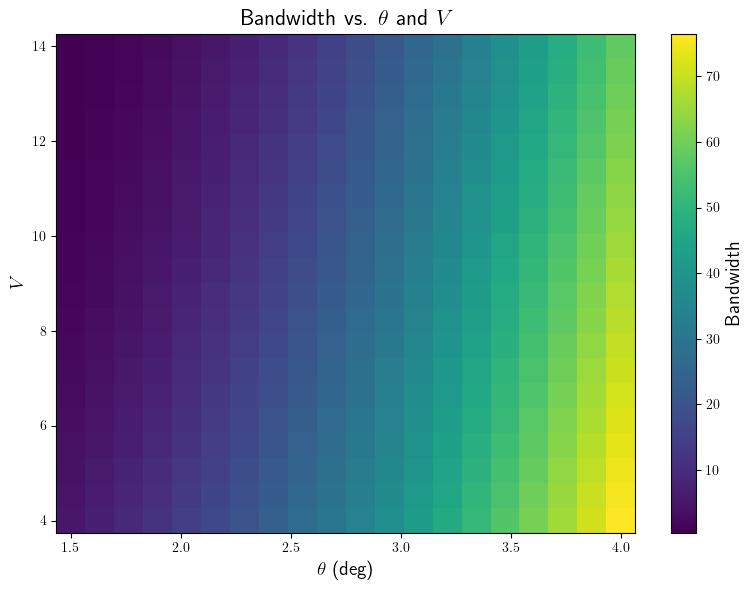

In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))

# pcolormesh wants cell edges; build them from the centers
def edges(c):
    c = np.asarray(c, float)
    mid = 0.5 * (c[:-1] + c[1:])
    return np.concatenate([[c[0] - (mid[0] - c[0])], mid, [c[-1] + (c[-1] - mid[-1])]])

TH, VV = np.meshgrid(edges(thetas), edges(Vs))
pcm = ax.pcolormesh(TH, VV, bw, cmap='viridis', shading='auto')

cbar = fig.colorbar(pcm, ax=ax)
cbar.set_label('Bandwidth', fontsize=14)

ax.set_xlabel(r'$\theta$ (deg)', fontsize=14)
ax.set_ylabel(r'$V$', fontsize=14)
ax.set_title('Bandwidth vs. $\\theta$ and $V$', fontsize=16)

plt.tight_layout()
plt.show()

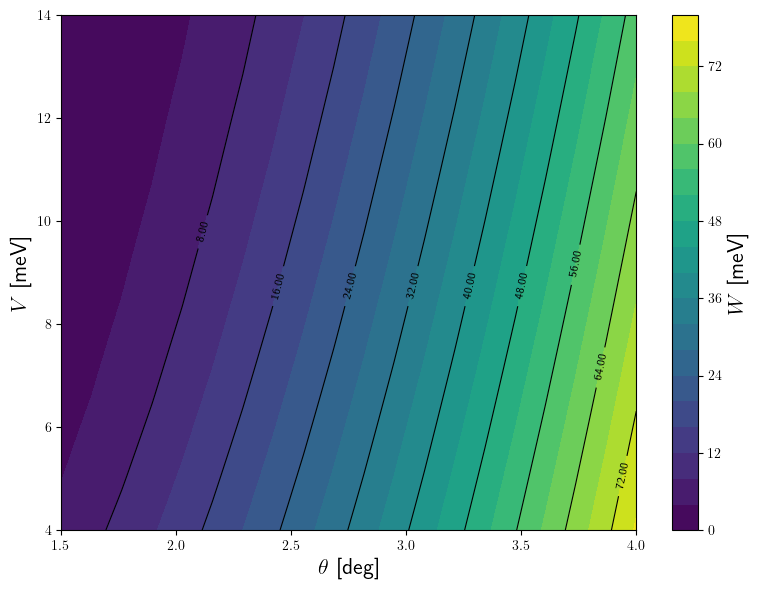

In [120]:
TH, VV = np.meshgrid(thetas, Vs)   # centers, not edges

fig, ax = plt.subplots(figsize=(8, 6))

# filled background for context
cf = ax.contourf(TH, VV, bw, levels=20, cmap='viridis')
cbar = fig.colorbar(cf, ax=ax)
cbar.set_label(r'$W$ [meV]', fontsize=16)

# equal-value contour lines on top
cs = ax.contour(TH, VV, bw, levels=10, colors='k', linewidths=0.8)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.2f')

ax.set_xlabel(r'$\theta$ [deg]', fontsize=16)
ax.set_ylabel(r'$V$ [meV]', fontsize=16)

plt.tight_layout()
plt.show()

In [106]:
def bandwidth_path(target_bw, thetas, Vs, bw):
    """
    Return the (theta, V) contour(s) where bandwidth == target_bw.

    Parameters
    ----------
    target_bw : float
        The bandwidth value to trace.
    thetas, Vs : 1D arrays
        Parameter grids (centers). bw has shape (len(Vs), len(thetas)).
    bw : 2D array
        Bandwidth values, bw[i, j] at (Vs[i], thetas[j]).

    Returns
    -------
    list of (N, 2) arrays
        Each array is one disconnected branch of the level curve,
        with columns [theta, V]. Empty list if the level isn't reached.
    """
    TH, VV = np.meshgrid(thetas, Vs)

    # compute contour without rendering
    fig = plt.figure()
    ax = fig.add_subplot(111)
    cs = ax.contour(TH, VV, bw, levels=[target_bw])
    plt.close(fig)

    paths = []
    for p in cs.get_paths():          # matplotlib >= 3.8
        v = p.vertices
        if len(v) > 0:
            paths.append(v)            # columns are already [theta, V]
    return paths

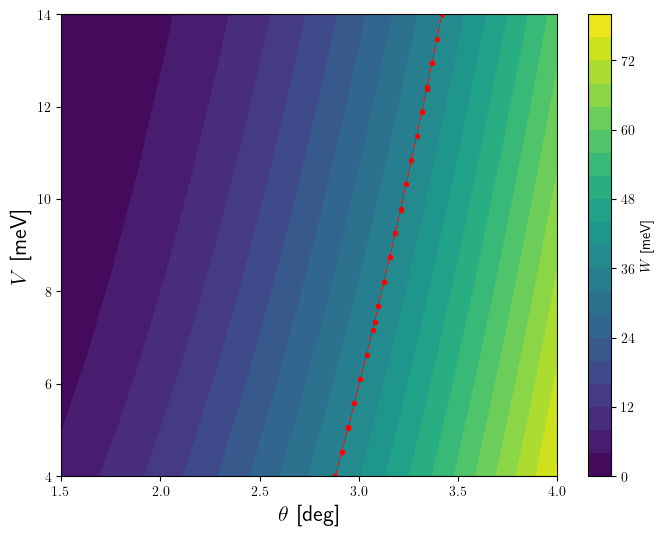

In [125]:
segments = bandwidth_path(36, thetas, Vs, bw)

if not segments:
    print("Bandwidth is outside the data range.")
else:
    fig, ax = plt.subplots(figsize=(8, 6))
    cf = ax.contourf(*np.meshgrid(thetas, Vs), bw, levels=20, cmap='viridis')
    fig.colorbar(cf, ax=ax, label=r'$W$ [meV]')
    for seg in segments:
        ax.plot(seg[:, 0], seg[:, 1], '-o', lw=.5, markersize=3, color='red')
    ax.set_xlabel(r'$\theta$ [deg]', fontsize=16)
    ax.set_ylabel(r'$V$ [meV]', fontsize=16)
    plt.show()

In [64]:
resk = 12
metric_length = []
J = []

scale = 4.0

Nx = 60
Ny = 60
resk = 15
D_gate = 1e6
eps_val = 10

for seg in segments:
    for i in tqdm(range(len(seg[:, 0]))):
        sys.theta_deg = seg[i, 0]
        sys.V = seg[i, 1]

        integral = sys.integrate_trace(Nx=resk, Ny=resk)
        metric_length.append(integral)

        k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

        x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
        y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
        X, Y = np.meshgrid(x, y)
        extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
        
        exchange = sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=eps_val)
        t1 = sys.hopping_integral(X, Y, k_points, order=1)
        U0 = sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate, epsilon=eps_val)
        J.append( 4 * (t1**2) / U0 - 2 * exchange)

100%|██████████| 12/12 [01:04<00:00,  5.35s/it]


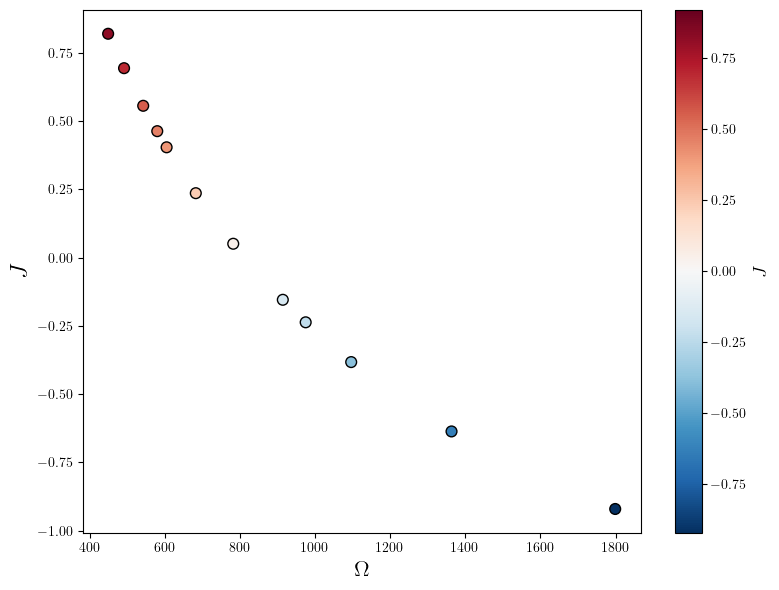

In [65]:
ii = np.arange(len(metric_length))

vmax = np.max(np.abs(J))
vmin = -vmax

fig, ax = plt.subplots(figsize=(8, 6))
sc = ax.scatter( metric_length, J, c=J, s=60, cmap='RdBu_r',
                edgecolor='k', vmin=vmin, vmax=vmax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r'$J$', fontsize=14)

ax.set_xlabel(r'$\Omega$', fontsize=16)
ax.set_ylabel(r'$J$', fontsize=18)
plt.tight_layout()
plt.show()

In [114]:
bw_list = np.linspace(20, 60, 10)
metric_length = []
J = []

scale = 4.0

Nx = 60
Ny = 60
resk = 15
D_gate = 1e6
eps_val = 10


for bw_target in tqdm(bw_list):
    segments = bandwidth_path(bw_target, thetas, Vs, bw)
    J_temp = []
    length_temp = []
    
    for seg in segments:
        for i in range(len(seg[:, 0])):
            sys.theta_deg = seg[i, 0]
            sys.V = seg[i, 1]

            integral = sys.integrate_trace(Nx=resk, Ny=resk)
            length_temp.append(integral / sys.aM**2)

            k_points = sys.mesh_k_unit_cell(Nx=18, Ny=18)

            x = np.linspace(-scale * sys.aM, scale * sys.aM, Nx)
            y = np.linspace(-scale * sys.aM, scale * sys.aM, Ny)
            X, Y = np.meshgrid(x, y)
            extent = [-scale * sys.aM, scale * sys.aM, -scale * sys.aM, scale * sys.aM]
            
            exchange = sys.exchange_interaction(X, Y, k_points, order=1, D=D_gate, epsilon=eps_val)
            t1 = sys.hopping_integral(X, Y, k_points, order=1)
            U0 = sys.nearest_neighbour_interaction(X, Y, k_points, order=0, D=D_gate, epsilon=eps_val)
            J_temp.append( 4 * (t1**2) / U0 - 2 * exchange)

    J.append(J_temp)
    metric_length.append(length_temp)

100%|██████████| 10/10 [22:17<00:00, 133.76s/it]


/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Users/higuera/Desktop/UniStuttgart/flatiron/project/moire_heterobilayers/.venv/lib/python3.12/site-packages/matplotlib/axes/_axes.py:4733: ComplexWarning: Casting complex values to real discards the imaginary part
  c = np.asanyarray(c, dtype=float)


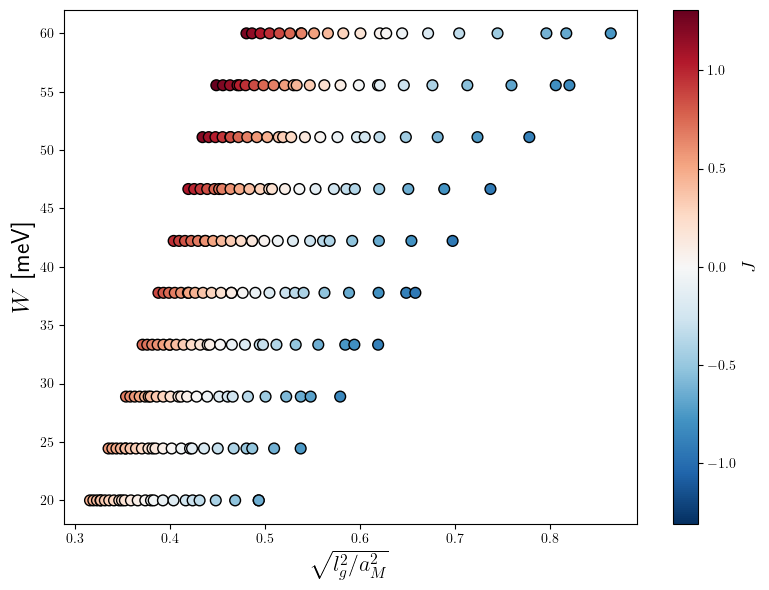

In [121]:
vmax = 0

for j in J:
    vmax = max(vmax, np.max(np.abs(j)))
vmin = -vmax

fig, ax = plt.subplots(figsize=(8, 6))

for i in range(len(bw_list)):
    temp_bw = bw_list[i] * np.ones(len(J[i]))
    #ax.scatter(metric_length[i::len(bw_list)], temp_bw, label=f'bw={bw_list[i]}', s=60, edgecolor='k')
    sc = ax.scatter( np.sqrt(metric_length[i]), temp_bw, c=J[i], s=60, cmap='RdBu_r',
                    edgecolor='k', vmin=vmin, vmax=vmax)

cbar = fig.colorbar(sc, ax=ax)
cbar.set_label(r'$J$', fontsize=14)

ax.set_xlabel(r'$\sqrt{l_g^2 / a_M^2}$', fontsize=16)
ax.set_ylabel(r'$W$ [meV]', fontsize=18)
plt.tight_layout()
plt.savefig("plots/bandwidth_metric.pdf", dpi=300)
plt.show()